In [1]:
# Cell 1 — Imports and paths

import torch
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

BASE_DIR = Path("D:/adaptive_federated_gnn")

DAY10_DIR = BASE_DIR / "outputs/day10"
DAY11_DIR = BASE_DIR / "outputs/day11"
DAY12_DIR = BASE_DIR / "outputs/day12"
DAY14_DIR = BASE_DIR / "outputs/day14"

DAY14_DIR.mkdir(parents=True, exist_ok=True)

print("Day 14 output:", DAY14_DIR)

Day 14 output: D:\adaptive_federated_gnn\outputs\day14


In [2]:
# Cell 2 — Load federated client data

CLIENT_FILE = DAY10_DIR / "federated_clients.pt"

clients = torch.load(
    CLIENT_FILE,
    map_location="cpu",
    weights_only=False
)

client_rows = []

for client_name, client_data in clients.items():

    features = client_data["edge_features"]
    labels = client_data["edge_labels"]

    client_rows.append({
        "client": client_name,
        "total_edges": len(labels),
        "benign_edges": int((labels == 0).sum()),
        "attack_edges": int((labels == 1).sum()),
        "feature_count": features.shape[1]
    })

client_df = pd.DataFrame(client_rows)

display(client_df)

client_df.to_csv(
    DAY14_DIR / "client_distribution.csv",
    index=False
)

,client,total_edges,benign_edges,attack_edges,feature_count
0,client_1,66755,29701,37054,67
1,client_2,66755,29701,37054,67
2,client_3,66756,29701,37055,67


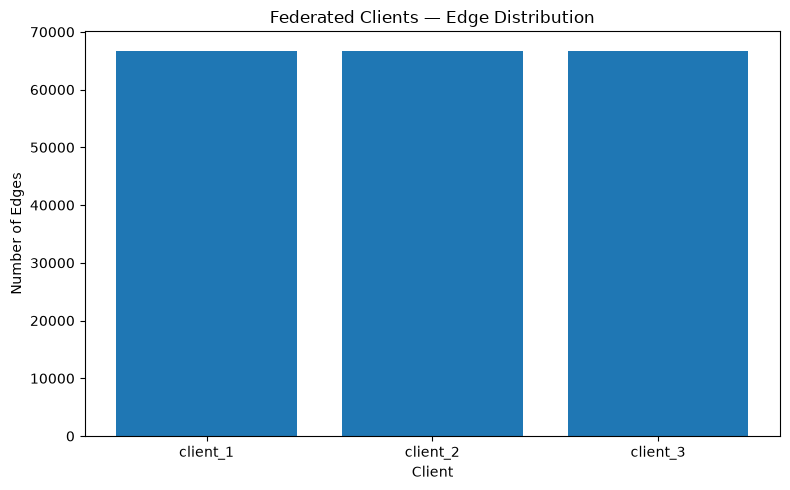

In [3]:
# Cell 3 — Compare client edge counts

plt.figure(figsize=(8, 5))

plt.bar(
    client_df["client"],
    client_df["total_edges"]
)

plt.title("Federated Clients — Edge Distribution")
plt.xlabel("Client")
plt.ylabel("Number of Edges")
plt.tight_layout()

plt.savefig(
    DAY14_DIR / "client_edge_distribution.png",
    dpi=150
)

plt.show()

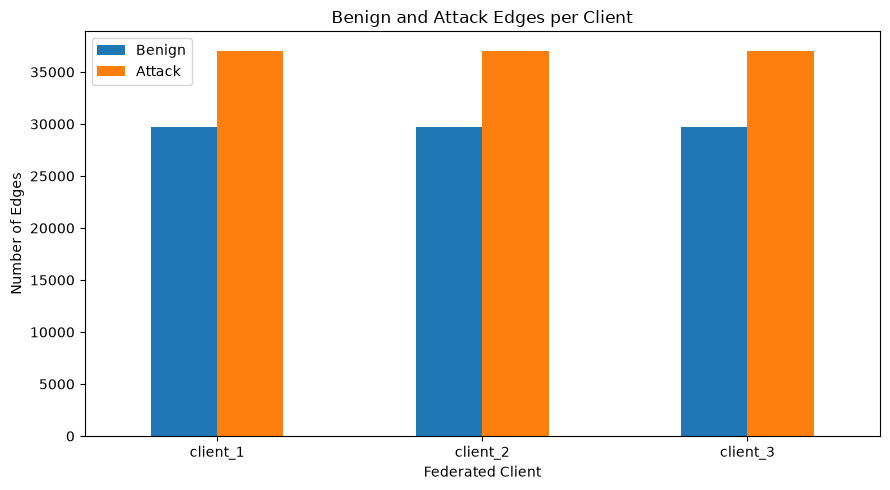

In [4]:
# Cell 4 — Benign versus attack edges

plot_df = client_df.set_index("client")[
    ["benign_edges", "attack_edges"]
]

plot_df.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Benign and Attack Edges per Client")
plt.xlabel("Federated Client")
plt.ylabel("Number of Edges")
plt.xticks(rotation=0)
plt.legend(["Benign", "Attack"])
plt.tight_layout()

plt.savefig(
    DAY14_DIR / "client_class_distribution.png",
    dpi=150
)

plt.show()

Local client evaluation metrics:


,client,edges,accuracy,precision,recall,f1,roc_auc,pr_auc
0,client_1,66755,0.996300,0.995477,0.997868,0.996671,0.998587,0.999318
1,client_2,66755,0.998547,0.999540,0.997841,0.998690,0.998848,0.999315
2,client_3,66756,0.994038,0.995004,0.994252,0.994628,0.998120,0.998688


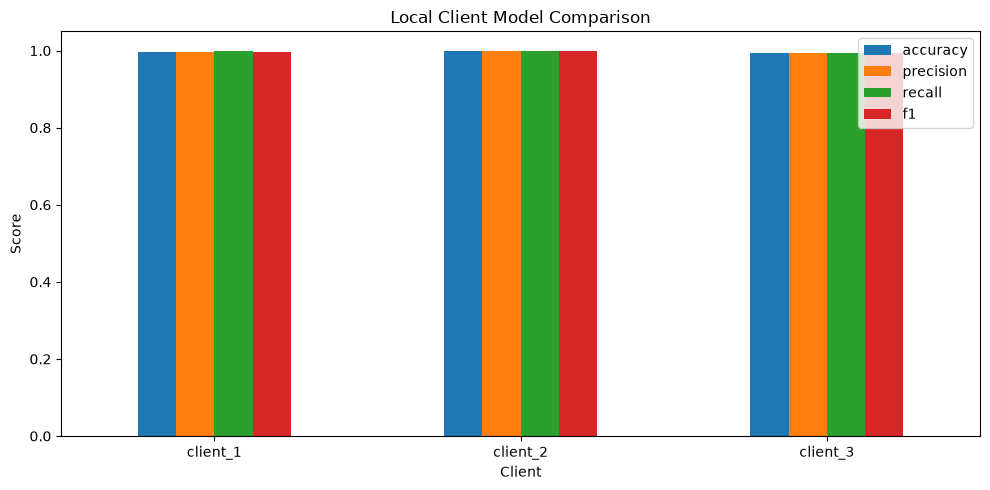

In [5]:
# Cell 5 — Load local training metrics

METRICS_FILE = DAY11_DIR / "local_client_metrics.csv"

if METRICS_FILE.exists():

    local_metrics = pd.read_csv(METRICS_FILE)

    print("Local client evaluation metrics:")
    display(local_metrics)

    metric_columns = [
        column for column in
        ["accuracy", "precision", "recall", "f1"]
        if column in local_metrics.columns
    ]

    if metric_columns:

        local_metrics.set_index("client")[
            metric_columns
        ].plot(
            kind="bar",
            figsize=(10, 5)
        )

        plt.title("Local Client Model Comparison")
        plt.xlabel("Client")
        plt.ylabel("Score")
        plt.ylim(0, 1.05)
        plt.xticks(rotation=0)
        plt.tight_layout()

        plt.savefig(
            DAY14_DIR / "local_model_comparison.png",
            dpi=150
        )

        plt.show()

else:
    print(
        "Day 11 metrics file not found. "
        "Complete Day 11 before running this comparison."
    )

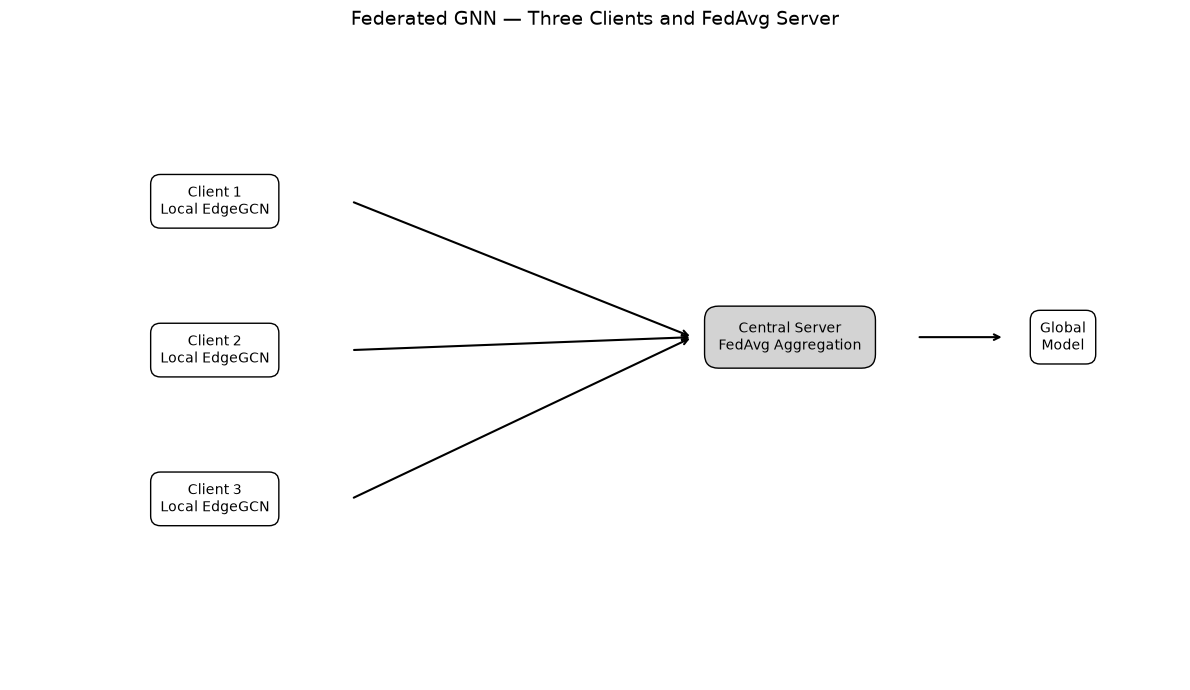

In [6]:
# Cell 6 — Federated learning architecture diagram

fig, ax = plt.subplots(figsize=(12, 7))

ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.axis("off")

# Client boxes
client_positions = [
    (0.5, 6.8),
    (0.5, 4.5),
    (0.5, 2.2)
]

for i, (x, y) in enumerate(client_positions, start=1):

    ax.text(
        x + 1.6,
        y + 0.6,
        f"Client {i}\nLocal EdgeGCN",
        ha="center",
        va="center",
        bbox=dict(
            boxstyle="round,pad=0.7",
            facecolor="white",
            edgecolor="black"
        )
    )

    ax.annotate(
        "",
        xy=(7.0, 5.3),
        xytext=(x + 3.0, y + 0.6),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.5
        )
    )

# Server
ax.text(
    8.0,
    5.3,
    "Central Server\nFedAvg Aggregation",
    ha="center",
    va="center",
    bbox=dict(
        boxstyle="round,pad=1",
        facecolor="lightgray",
        edgecolor="black"
    )
)

# Global model
ax.annotate(
    "",
    xy=(10.2, 5.3),
    xytext=(9.3, 5.3),
    arrowprops=dict(
        arrowstyle="->",
        linewidth=1.5
    )
)

ax.text(
    10.8,
    5.3,
    "Global\nModel",
    ha="center",
    va="center",
    bbox=dict(
        boxstyle="round,pad=0.7",
        facecolor="white",
        edgecolor="black"
    )
)

ax.set_title(
    "Federated GNN — Three Clients and FedAvg Server",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    DAY14_DIR / "federated_learning_architecture.png",
    dpi=180
)

plt.show()

In [7]:
# Cell 7 — Verify Day 11 and Day 12 model files

files_to_check = [
    DAY11_DIR / "client_1_model.pt",
    DAY11_DIR / "client_2_model.pt",
    DAY11_DIR / "client_3_model.pt",
    DAY12_DIR / "global_model_round1.pt"
]

for file_path in files_to_check:

    print(
        file_path.name,
        "->",
        "OK" if file_path.exists() else "MISSING"
    )

client_1_model.pt -> OK
client_2_model.pt -> OK
client_3_model.pt -> OK
global_model_round1.pt -> OK


In [8]:
# Cell 8 — Save workflow summary

workflow_summary = pd.DataFrame([
    {
        "stage": 1,
        "component": "Client 1",
        "operation": "Local EdgeGCN training"
    },
    {
        "stage": 2,
        "component": "Client 2",
        "operation": "Local EdgeGCN training"
    },
    {
        "stage": 3,
        "component": "Client 3",
        "operation": "Local EdgeGCN training"
    },
    {
        "stage": 4,
        "component": "Central server",
        "operation": "FedAvg parameter aggregation"
    },
    {
        "stage": 5,
        "component": "Global model",
        "operation": "Federated model output"
    }
])

display(workflow_summary)

workflow_summary.to_csv(
    DAY14_DIR / "federated_workflow_summary.csv",
    index=False
)

print("Day 14 visualization outputs saved.")

,stage,component,operation
0,1,Client 1,Local EdgeGCN training
1,2,Client 2,Local EdgeGCN training
2,3,Client 3,Local EdgeGCN training
3,4,Central server,FedAvg parameter aggregation
4,5,Global model,Federated model output


Day 14 visualization outputs saved.
